# High Frequency Words: An Astronomy Corpus
**Anthony Roman**  
**DATA 620 - Week Eight Assignment**

## Introduction

In this assignment, word frequency statistics in *Astronomy for Amateurs* by Camille Flammarion, translated by Frances A. Welby will be carried out. This text was chosen by me due to my education and interest in scientific writing.

This analysis will consist of identifying the number of different words used in the text, finding out what part of the most frequent words contributes half of the total number of words, and studying 200 most frequent words. In addition, the conformity of the found frequencies to Zipf's law will be considered.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from collections import Counter
import re
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

plt.rcParams.update({
    "figure.dpi": 120,
    "font.size": 11
})

print("Libraries imported successfully.")

Libraries imported successfully.


## 1. Corpus Selection

The corpus to be analyzed includes twelve chapters from "Astronomy for Amateurs" available at Project Gutenberg. Corpus is a set of texts used in language analysis, which may contain only one book.

The analysis will not include publisher's data, dedication, foreword, table of contents, index, notes and Project Gutenberg license. The chapter titles, tables, and captions to illustrations included in each chapter will be kept.

Using one book on astronomy makes it possible to demonstrate the features of scientific language use in one particular case. However, the vocabulary of this book depends on its subject matter, time period, author and translator.

Source: [Astronomy for Amateurs, Project Gutenberg](https://www.gutenberg.org/ebooks/25267)

In [2]:
source_url = "https://www.gutenberg.org/cache/epub/25267/pg25267.txt"

file_path = Path("data/astronomy_for_amateurs.txt")
file_path.parent.mkdir(parents=True, exist_ok=True)

if not file_path.exists():
    with urlopen(source_url, timeout=60) as response:
        downloaded_text = response.read().decode("utf-8-sig")

    file_path.write_text(downloaded_text, encoding="utf-8")

raw_text = file_path.read_text(encoding="utf-8")

start = re.search(r"(?m)^CHAPTER I\s*$", raw_text)
assert start is not None, "Could not find Chapter I."

remaining_text = raw_text[start.start():]
end = re.search(r"(?m)^INDEX\s*$", remaining_text)
assert end is not None, "Could not find the index."

corpus_text = remaining_text[:end.start()]

chapters = re.findall(r"(?m)^CHAPTER [IVX]+\s*$", corpus_text)
assert len(chapters) == 12, "Expected twelve chapters."

print(f"Chapters retained: {len(chapters)}")
print(f"Characters in the corpus: {len(corpus_text):,}")
print("\nOpening excerpt:\n")
print(corpus_text[:500])

Chapters retained: 12
Characters in the corpus: 365,448

Opening excerpt:

CHAPTER I

THE CONTEMPLATION OF THE HEAVENS


The crimson disk of the Sun has plunged beneath the Ocean. The sea has
decked itself with the burning colors of the orb, reflected from the
Heavens in a mirror of turquoise and emerald. The rolling waves are gold
and silver, and break noisily on a shore already darkened by the
disappearance of the celestial luminary.

We gaze regretfully after the star of day, that poured its cheerful rays
anon so generously over many who were intoxicated with gaiety


## 2. Defining Unique Words

Before word counts are performed, there needs to be a difference between tokens and types. One token is one occurrence of a word, while one type is a distinct word. For instance, the string “star star planet” consists of three tokens but only two types.

For this particular analysis, one unique word is defined as a distinct lowercase alphabetic token. The following rules are utilized:

- Convert the text to lowercase so that “Sun” and “sun” become the same word.
- Do not include numbers and punctuation, but keep apostrophes in words.
- Break down hyphenated phrases into separate words.
- Treat distinct word forms separately, including “star” and “stars.”
- Keep common words like “the,” “of,” and “and.”

The common words are kept because the objective is to perform a frequency analysis on all words in the text. Their omission would alter the word distribution and the amount of words that cover half of the text.

In [3]:
normalized_text = unicodedata.normalize("NFKC", corpus_text)
normalized_text = normalized_text.lower().replace("’", "'")

tokens = re.findall(r"[^\W\d_]+(?:'[^\W\d_]+)*", normalized_text)

word_counts = Counter(tokens)

total_tokens = len(tokens)
unique_words = len(word_counts)

print(f"Total word occurrences (tokens): {total_tokens:,}")
print(f"Unique words (types): {unique_words:,}")

print("\nFirst 20 tokens:")
print(tokens[:20])

Total word occurrences (tokens): 60,965
Unique words (types): 6,233

First 20 tokens:
['chapter', 'i', 'the', 'contemplation', 'of', 'the', 'heavens', 'the', 'crimson', 'disk', 'of', 'the', 'sun', 'has', 'plunged', 'beneath', 'the', 'ocean', 'the', 'sea']


## 3. How Many Unique Words Account for Half of the Text?

The corpus has 60,965 total words and 6,233 distinct words based on the cleaning criteria mentioned earlier. Repeating words add up to the total words but do not make any addition to distinct words.

Subsequently, I sort the words according to frequency starting with the highest and then find out the cumulative counts of words. This helps to identify the minimum number of distinct words that form 50 percent or more of the total words.

It is not the same as half of the distinct words. Rather, the purpose here is to find out how many percent of text is made by repeating words.

In [4]:
frequency = pd.DataFrame(
    sorted(word_counts.items(), key=lambda item: (-item[1], item[0])),
    columns=["word", "count"]
)

frequency.insert(0, "rank", np.arange(1, len(frequency) + 1))

frequency["relative_frequency"] = frequency["count"] / total_tokens
frequency["cumulative_count"] = frequency["count"].cumsum()
frequency["cumulative_share"] = (
    frequency["cumulative_count"] / total_tokens
)

half_index = np.searchsorted(
    frequency["cumulative_count"].to_numpy(),
    total_tokens / 2
)

words_for_half = int(half_index + 1)
coverage = frequency.iloc[half_index]["cumulative_share"]

print(f"Unique words needed to reach 50%: {words_for_half}")
print(f"Share of total word occurrences: {coverage:.2%}")

display(
    frequency.iloc[max(0, half_index - 2):half_index + 3][
        ["rank", "word", "count", "cumulative_count", "cumulative_share"]
    ].round(4)
)

Unique words needed to reach 50%: 64
Share of total word occurrences: 50.04%


,rank,word,count,cumulative_count,cumulative_share
61,62,little,117,30278,0.4966
62,63,his,114,30392,0.4985
63,64,round,114,30506,0.5004
64,65,them,114,30620,0.5023
65,66,when,114,30734,0.5041


### Interpretation

The 64 common words constitute approximately 50.04% of the occurrences of all words in the corpus. In fact, the first 63 words only make up 49.85%, which means 64 is the lowest number for this purpose.

These 64 words constitute approximately 1.03% of the total 6,233 common words. It proves that a tiny percentage of words constitutes a high percentage of the text.

Now I select the 200 most common words and calculate their relative frequencies. The relative frequency of each word is equal to its occurrence divided by the total number of occurrences of all words in the corpus.

In [5]:
top200 = frequency.head(200).copy()

top200_table = top200[
    ["rank", "word", "count", "relative_frequency"]
].copy()

top200_table["relative_frequency"] = (
    top200_table["relative_frequency"] * 100
).round(4)

top200_table = top200_table.rename(
    columns={"relative_frequency": "relative_frequency_percent"}
)

with pd.option_context("display.max_rows", 200):
    display(top200_table.set_index("rank"))

top200_coverage = top200["relative_frequency"].sum()

print(
    f"The 200 most frequent words account for "
    f"{top200_coverage:.2%} of all word occurrences."
)

,word,count,relative_frequency_percent
rank,,,
1,the,5854,9.6022
2,of,3221,5.2834
3,and,1531,2.5113
4,to,1335,2.1898
5,in,1330,2.1816
6,is,1191,1.9536
7,a,1175,1.9273
8,that,811,1.3303
9,it,681,1.1170


The 200 most frequent words account for 63.90% of all word occurrences.


## 5. Relative Frequency of the 200 Most Common Words

The 200 most frequently used words make up about 63.90% of all word occurrences within the text corpus.

The graph shown below is plotted using the word rank on the X-axis and relative frequency on the Y-axis. Word rank 1 corresponds to the most frequently used word, whereas Word rank 200 corresponds to the least frequently used word.

Relative frequency refers to the proportion of occurrences of each word against all word occurrences in the complete corpus.

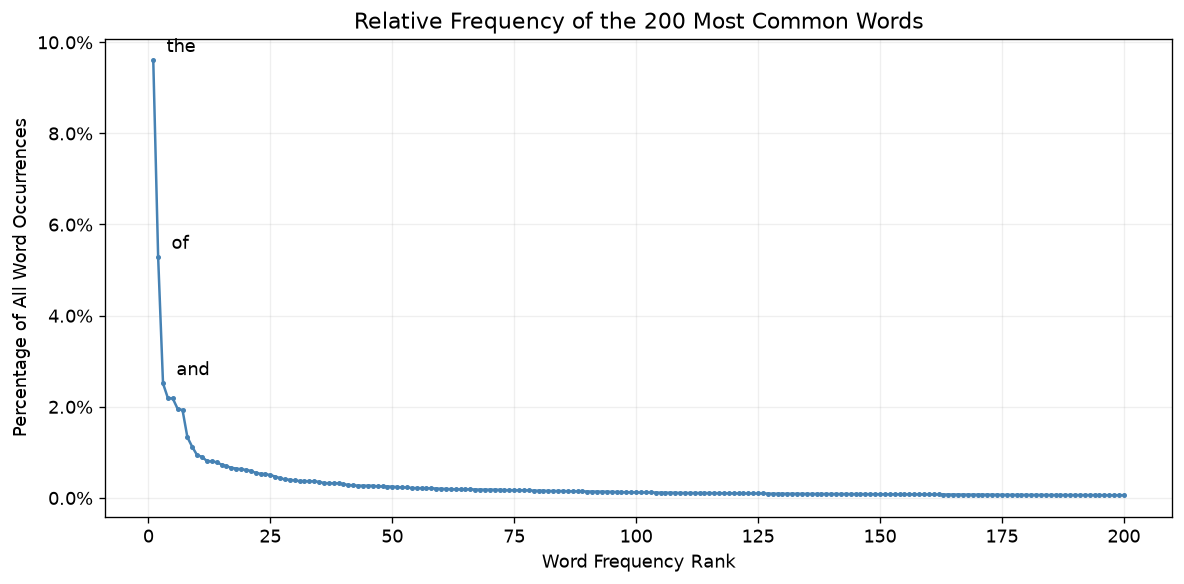

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    top200["rank"],
    top200["relative_frequency"],
    color="steelblue",
    marker=".",
    markersize=4
)

for row in top200.head(3).itertuples():
    ax.annotate(
        row.word,
        (row.rank, row.relative_frequency),
        xytext=(8, 5),
        textcoords="offset points"
    )

ax.set_title("Relative Frequency of the 200 Most Common Words")
ax.set_xlabel("Word Frequency Rank")
ax.set_ylabel("Percentage of All Word Occurrences")

ax.yaxis.set_major_formatter(PercentFormatter(1))

ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## 6. Does the Distribution Follow Zipf's Law?

In the relative frequency graph, some words are seen to occur frequently, then there are others that occur with relatively lower frequencies. Words like “the,” “of,” and “and” occur at the top because they are used for common grammatical purposes.

According to Zipf’s law, the frequency of a word is almost inversely proportional to its rank. This means that if the first word were to occur once, the second would occur approximately half as much, while the tenth would occur one-tenth of that many times.

To check if this is true, I draw a graph of frequency versus rank on logarithmic scales on the two axes. In accordance with the simplest version of Zipf’s law, the points would form a straight line whose slope will be -1.

I draw a line on the log-log plot of rank and relative frequency for the top 200 words. The slope and R-square values give descriptive information about the data, but they don’t constitute any proof of Zipf’s law in this case.

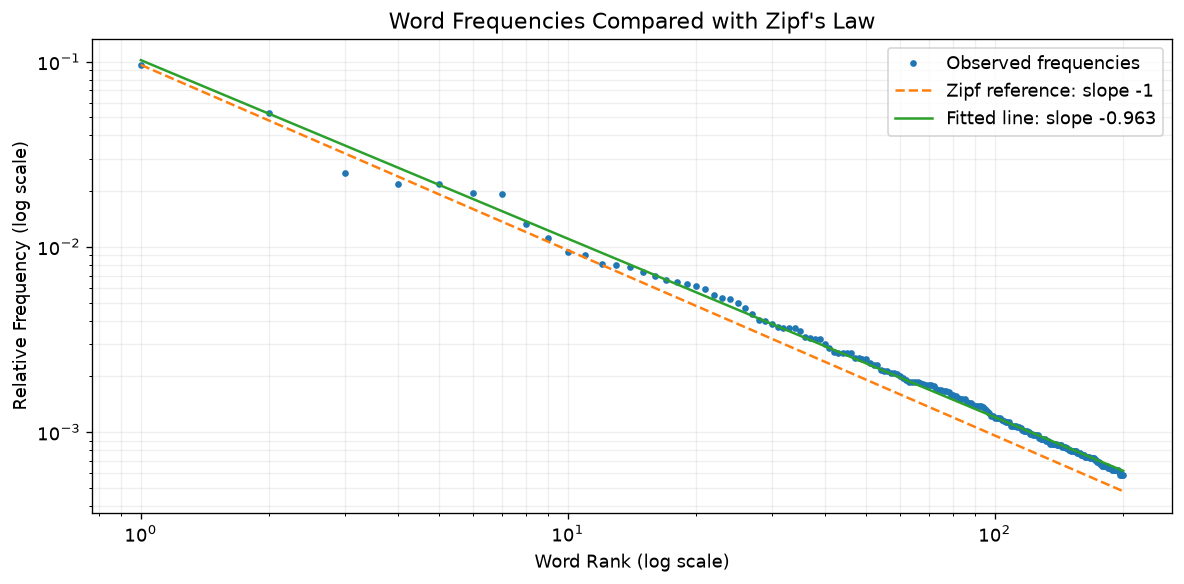

Fitted slope: -0.9632
Log-log R-squared: 0.9969


In [7]:
log_rank = np.log10(top200["rank"].to_numpy())
log_frequency = np.log10(top200["relative_frequency"].to_numpy())

slope, intercept = np.polyfit(log_rank, log_frequency, 1)
fitted_log_frequency = intercept + slope * log_rank

residual_sum = np.sum(
    (log_frequency - fitted_log_frequency) ** 2
)
total_sum = np.sum(
    (log_frequency - log_frequency.mean()) ** 2
)
r_squared = 1 - residual_sum / total_sum

zipf_reference = (
    top200.iloc[0]["relative_frequency"] / top200["rank"]
)

fig, ax = plt.subplots(figsize=(10, 5))

ax.loglog(
    top200["rank"],
    top200["relative_frequency"],
    "o",
    markersize=3,
    label="Observed frequencies"
)

ax.loglog(
    top200["rank"],
    zipf_reference,
    "--",
    label="Zipf reference: slope -1"
)

ax.loglog(
    top200["rank"],
    10 ** fitted_log_frequency,
    label=f"Fitted line: slope {slope:.3f}"
)

ax.set_title("Word Frequencies Compared with Zipf's Law")
ax.set_xlabel("Word Rank (log scale)")
ax.set_ylabel("Relative Frequency (log scale)")
ax.legend()
ax.grid(alpha=0.2, which="both")

fig.tight_layout()
plt.show()

print(f"Fitted slope: {slope:.4f}")
print(f"Log-log R-squared: {r_squared:.4f}")

### Interpretation of Zipf's Law Results

The estimated slope coefficient is approximately -0.9632, which is very close to the slope of -1 predicted by the simplest version of Zipf's law. The log-log R-squared is approximately 0.9969, which means that the fitted line fits well the log-frequency data for the top 200 words.

Additionally, one can see that the frequency distribution follows approximately a straight line on logarithmic axes. These two facts together imply that the frequency distribution can be considered consistent with Zipf's law although it does not coincide with the reference line.

Discrepancies might be caused by the book's astronomy-specific vocabulary, unique writing style, and relatively small number of words. The analysis was conducted only for the 200 most frequent words. A high R-squared value does not mean that the whole vocabulary follows a power law.

## 7. Comparison with Other Corpora

This corpus' frequency distribution will be affected by the astronomical subject matter that it covers. “Sun,” “Earth,” “stars,” and “moon” are words which will have higher frequencies in this corpus compared to others in a corpus made up of general English texts. Common grammatical words like “the,” “of,” and “and” will be frequent regardless of the corpus.

The era from which the text is written, as well as the language it was translated into, affect the words used in the book. Words in contemporary books will differ in frequency; those in conversation, fiction, newspaper articles, and social media will differ too.

The corpus' frequency distribution will not be equivalent to that of “all words in all corpora.” This would depend on the selection of languages, genres, eras, and methods of analysis. The above observations are, thus, expected trends and not measured differences between the two corpora.

The table below evaluates the frequency and rank of some astronomy-related words in the corpus.

In [8]:
astronomy_terms = [
    "sun", "earth", "stars", "moon", "planets", "astronomy"
]

astronomy_table = frequency.loc[
    frequency["word"].isin(astronomy_terms),
    ["rank", "word", "count", "relative_frequency"]
].copy()

astronomy_table["relative_frequency"] = (
    astronomy_table["relative_frequency"] * 100
).round(3)

astronomy_table = astronomy_table.rename(
    columns={"relative_frequency": "relative_frequency_percent"}
)

display(astronomy_table.set_index("rank"))

,word,count,relative_frequency_percent
rank,,,
19,sun,384,0.630
24,earth,318,0.522
34,stars,222,0.364
40,moon,182,0.299
138,planets,53,0.087
402,astronomy,18,0.030


## Conclusion

According to the cleaning rules presented above, there are 60,965 occurrences of words and 6,233 different words in this astronomy corpus. Just 64 different words compose about half of the text, and 200 most frequently occurring words make up about 63.90 percent of the whole amount of words.

The frequency distribution is quite similar to the Zipf's law. The 200 most frequent words in logarithmic axes demonstrate an almost linear dependence with a slope of -0.9632, which is very close to -1 that is expected according to the Zipf's law. Nevertheless, this only means that there are many words in this vocabulary that have frequency distributions that do not correspond to the Zipf's law.

So, the results show how a text can be dominated by just several words and how vocabulary is influenced by the subject of a text.

## References

- Flammarion, C. (1904). *Astronomy for amateurs* (F. A. Welby, Trans.). D. Appleton and Company. Project Gutenberg. https://www.gutenberg.org/ebooks/25267

- Project Gutenberg. *Astronomy for amateurs: Plain-text edition*. https://www.gutenberg.org/cache/epub/25267/pg25267.txt

- DATA 620. *Assignment: High Frequency Words*. Week Eight assignment instructions.